# Chapter 18 — Delta Hedging, Examples 18.1 and 18.2

The dealer's problem of Section 18.1 and the two hedging programs of
Tables 18.1 and 18.2, rebuilt transaction by transaction.

| Section | What it reproduces |
|---|---|
| 1 | The position, and why naked and covered are both bets |
| 2 | The weekly program, and Table 18.1 (finishes in the money) |
| 3 | Table 18.2 (finishes out of the money) |
| 4 | Reading them — Example 18.2's two round trips |
| 5 | Why the two costs differ: the residual, and how it falls with $n$ |

The stock paths are the chapter's own, given as data; they are simulated paths,
not reproducible from a formula, so the notebook takes them as printed and
rebuilds everything else. **Every delta, every share count and both hedging costs
are computed here**, not copied.

Standard library, plus NumPy and SciPy in the last section only.

In [1]:
from math import log, sqrt, exp
from statistics import NormalDist

N = NormalDist().cdf

S0, K, r, SIGMA, WEEKS, N_OPT = 63.0, 64.0, 0.04, 0.22, 18, 100_000


def show(label, got, printed, tol=6e-4):
    """Print a computed value beside the one the chapter prints."""
    flag = "ok" if abs(got - printed) <= tol * max(1.0, abs(printed)) else "DIFFERS"
    print("%-42s %14.4f   book %12.4f   %s" % (label, got, printed, flag))


def bs_call(S, K, T, r, sig):
    if T <= 0:
        return max(S - K, 0.0)
    d1 = (log(S / K) + (r + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    return S * N(d1) - K * exp(-r * T) * N(d1 - sig * sqrt(T))


def delta(S, T, K=K, r=r, sig=SIGMA):
    """N(d1); at expiration the step function the smooth delta converges to."""
    if T <= 0:
        return 1.0 if S > K else 0.0
    return N((log(S / K) + (r + 0.5 * sig * sig) * T) / (sig * sqrt(T)))


T0 = WEEKS / 52.0
price = bs_call(S0, K, T0, r, SIGMA)
premium = price * N_OPT
show("Black-Scholes-Merton price per option", price, 3.1944)
show("premium received", premium, 319438, tol=1e-5)
show("premium compounded to expiration", premium * exp(r * T0), 323900, tol=1e-4)
import matplotlib.pyplot as plt

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well as
# color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

Black-Scholes price per option                     3.1944   book       3.1944   ok
premium received                              319437.8188   book  319438.0000   ok
premium compounded to expiration              323891.5664   book  323900.0000   ok


## 1. Neither doing nothing nor buying the stock is a hedge

Both alternatives convert the dealer's position into a directional bet, in
opposite directions, and each can lose about twice the premium.

In [2]:
print("%19s %16s %16s" % ("stock at expiration", "naked", "covered"))
for S_T in (54.0, 74.0):
    owed = max(S_T - K, 0.0) * N_OPT
    naked = premium - owed
    covered = premium - owed + (S_T - S0) * N_OPT
    print("%19.0f %16s %16s" % (S_T, "{:,.0f}".format(naked), "{:,.0f}".format(covered)))
show("naked, stock at 54", premium, 319438, tol=1e-5)
show("naked, stock at 74", premium - 10.0 * N_OPT, -680562, tol=1e-5)
show("covered, stock at 54", premium - 0 + (54 - 63) * N_OPT, -580562, tol=1e-5)
show("covered, stock at 74", premium - 10.0 * N_OPT + (74 - 63) * N_OPT, 419438, tol=1e-5)

stock at expiration            naked          covered
                 54          319,438         -580,562
                 74         -680,562          419,438
naked, stock at 54                            319437.8188   book  319438.0000   ok
naked, stock at 74                           -680562.1812   book -680562.0000   ok
covered, stock at 54                         -580562.1812   book -580562.0000   ok
covered, stock at 74                          419437.8188   book  419438.0000   ok


## 2. The weekly program — Table 18.1

The dealer borrows to buy $\Delta \times 100{,}000$ shares at week 0 and each week
borrows or repays to restore delta neutrality. The cumulative cost column
compounds the previous balance at 4% and adds the week's trade, so it is the
outstanding debt. At expiration the shares are delivered against the strike.

In [3]:
def run_hedge(path, verbose=True):
    """Rebuild a hedging table from a weekly stock path. Costs in $000."""
    prev_delta, cum, rows = 0.0, 0.0, []
    for week, S in enumerate(path):
        d = delta(S, (WEEKS - week) / 52.0)
        shares = (d - prev_delta) * N_OPT
        cost = shares * S / 1000.0
        cum = cost if week == 0 else cum + cum * r / 52.0 + cost
        interest = cum * r / 52.0
        rows.append((week, S, d, shares, cost, cum, interest))
        prev_delta = d
    if verbose:
        print("%4s %7s %7s %11s %10s %11s %8s"
              % ("week", "stock", "delta", "shares", "cost", "cumulative", "interest"))
        for w, S, d, sh, c, cu, it in rows:
            print("%4d %7.2f %7.3f %11s %10.1f %11.1f %8.1f"
                  % (w, S, d, "{:,.0f}".format(sh), c, cu, it if w < WEEKS else 0.0))
    return rows


ITM = [63.00, 61.12, 62.51, 60.86, 58.46, 61.57, 62.02, 62.03, 61.55, 63.48,
       61.94, 64.41, 64.71, 63.86, 63.25, 66.43, 70.36, 69.67, 66.04]

rows_itm = run_hedge(ITM)
cost_itm = rows_itm[-1][5] - K * N_OPT / 1000.0        # shares delivered on exercise
print()
show("cumulative cost at week 18", rows_itm[-1][5], 6736.8, tol=2e-4)
show("cost of hedging the option, $000", cost_itm, 336.8, tol=2e-3)

week   stock   delta      shares       cost  cumulative interest
   0   63.00   0.520      51,995     3275.7      3275.7      2.5
   1   61.12   0.421      -9,889     -604.4      2673.8      2.1
   2   62.51   0.488       6,651      415.8      3091.6      2.4
   3   60.86   0.394      -9,362     -569.7      2524.2      1.9
   4   58.46   0.261     -13,343     -780.0      1746.1      1.3
   5   61.57   0.418      15,788      972.1      2719.5      2.1
   6   62.02   0.438       1,915      118.8      2840.4      2.2
   7   62.03   0.431        -692      -43.0      2799.6      2.2
   8   61.55   0.391      -3,959     -243.7      2558.1      2.0
   9   63.48   0.513      12,183      773.4      3333.5      2.6
  10   61.94   0.396     -11,724     -726.2      2609.8      2.0
  11   64.41   0.574      17,822     1147.9      3759.8      2.9
  12   64.71   0.597       2,360      152.7      3915.4      3.0
  13   63.86   0.523      -7,417     -473.7      3444.7      2.6
  14   63.25   0.455     

## 3. The same position, a path that expires worthless — Table 18.2

Delta walks down to zero and the last trade liquidates the position. No decision
is taken at expiration: the program converges to the payoff automatically, because
$N(d_1)$ becomes a step function.

In [4]:
OTM = [63.00, 61.60, 63.45, 61.36, 61.57, 61.08, 59.75, 58.01, 58.38, 61.22,
       58.88, 62.68, 64.54, 64.24, 66.55, 64.57, 63.73, 62.86, 60.90]

rows_otm = run_hedge(OTM)
cost_otm = rows_otm[-1][5]                              # expires worthless, no shares held
print()
show("cost of hedging the option, $000", cost_otm, 309.3, tol=6e-4)
print()
print("delta at week 18: in the money %.3f, out of the money %.3f"
      % (rows_itm[-1][2], rows_otm[-1][2]))

week   stock   delta      shares       cost  cumulative interest
   0   63.00   0.520      51,995     3275.7      3275.7      2.5
   1   61.60   0.446      -7,443     -458.5      2819.7      2.2
   2   63.45   0.536       9,080      576.1      3398.0      2.6
   3   61.36   0.421     -11,549     -708.6      2692.0      2.1
   4   61.57   0.426         474       29.2      2723.2      2.1
   5   61.08   0.390      -3,530     -215.6      2509.7      1.9
   6   59.75   0.305      -8,524     -509.3      2002.3      1.5
   7   58.01   0.201     -10,372     -601.7      1402.2      1.1
   8   58.38   0.205         346       20.2      1423.5      1.1
   9   61.22   0.358      15,323      938.1      2362.6      1.8
  10   58.88   0.197     -16,084     -947.1      1417.4      1.1
  11   62.68   0.440      24,278     1521.8      2940.3      2.3
  12   64.54   0.584      14,383      928.3      3870.8      3.0
  13   64.24   0.558      -2,599     -167.0      3706.9      2.9
  14   66.55   0.765     

## 4. Reading them — Example 18.2

Two round trips carry the argument. In Table 18.1 the stock falls to 58.46 and
the dealer **sells** 13,343 shares, then it rises to 61.57 and the dealer **buys**
15,788 back \$3.11 higher. In Table 18.2 weeks 13 to 15 oscillate 64.24, 66.55,
64.57, ending a third of a dollar from where they started, and the hedge loses a tenth
of the premium.

Nothing was mismanaged. Delta hedging sells low and buys high by construction,
and the accumulated cost of doing so is the option premium.

In [5]:
def round_trip(rows, w_sell, w_buy):
    _, S1, _, sh1, _, _, _ = rows[w_sell]
    _, S2, _, sh2, _, _, _ = rows[w_buy]
    return S1, sh1, S2, sh2, min(abs(sh1), abs(sh2)) * (S2 - S1)


S1, sh1, S2, sh2, loss = round_trip(rows_itm, 4, 5)
print("Table 18.1, weeks 4-5: sold {:,.0f} at {:.2f}, bought {:,.0f} back at {:.2f}"
      .format(-sh1, S1, sh2, S2))
show("loss on that round trip", loss, 41500, tol=2e-2)

S1, sh1, S2, sh2, loss = round_trip(rows_otm, 14, 15)
print()
print("Table 18.2, weeks 13-15: bought {:,.0f} at {:.2f}, sold {:,.0f} back at {:.2f}"
      .format(sh1, S1, -sh2, S2))
show("loss on that whipsaw", abs(min(abs(sh1), abs(sh2)) * (S2 - S1)), 33800, tol=2e-2)
show("as a share of the premium, %", 100 * abs(min(abs(sh1), abs(sh2)) * (S2 - S1)) / premium,
     10.6, tol=2e-2)

print()
compounded = premium * exp(r * T0)
show("premium compounded to expiration", compounded, 323900, tol=1e-4)
show("in-the-money path, vs premium, %", 100 * (cost_itm * 1000 / compounded - 1), 4.0, tol=2e-2)
show("out-of-the-money path, vs premium, %", 100 * (cost_otm * 1000 / compounded - 1), -4.5,
     tol=2e-2)

Table 18.1, weeks 4-5: sold 13,343 at 58.46, bought 15,788 back at 61.57
loss on that round trip                        41497.6480   book   41500.0000   ok

Table 18.2, weeks 13-15: bought 20,684 at 66.55, sold 17,061 back at 64.57
loss on that whipsaw                           33780.2300   book   33800.0000   ok
as a share of the premium, %                      10.5749   book      10.6000   ok

premium compounded to expiration              323891.5664   book  323900.0000   ok
in-the-money path, vs premium, %                   3.9975   book       4.0000   ok
out-of-the-money path, vs premium, %              -4.5041   book      -4.5000   ok


## 5. Why the two costs differ

Eighteen weekly rebalances is not many. Discrete hedging does not reproduce the payoff; it
reproduces it *on average*, and the residual is what Table 18.3 measures. The experiment
below repeats it: the mean cost converges to the premium and the standard deviation falls
as $1/\sqrt{n}$.

The paths below are simulated with a **real-world drift of 10%** against a 4%
rate, deliberately; the mean cost still comes back to the premium, which is
Chapter 13's principle in numerical form: $\mu$ cancels.

In [6]:
import numpy as np
from scipy.special import erf


def hedge_cost_mc(n_rebal, n_paths=20_000, mu=0.10, seed=3, cost_rate=0.0):
    """Cost of the program in time-0 dollars, per option, over many paths.

    cost_rate charges that fraction of the value of each rebalancing trade, the
    chapter's trading-cost model (Table 18.7); the expiration unwind is not charged.
    """
    rng = np.random.default_rng(seed)
    dt = T0 / n_rebal
    z = rng.standard_normal((n_paths, n_rebal))
    z = np.concatenate([z, -z])                        # antithetic
    logS = np.log(S0) + np.cumsum((mu - 0.5 * SIGMA ** 2) * dt + SIGMA * sqrt(dt) * z, axis=1)
    S = np.exp(logS)
    S = np.hstack([np.full((len(S), 1), S0), S])

    prev = np.zeros(len(S))
    cash = np.zeros(len(S))
    for i in range(n_rebal):
        T_left = T0 - i * dt
        d1 = (np.log(S[:, i] / K) + (r + 0.5 * SIGMA ** 2) * T_left) / (SIGMA * sqrt(T_left))
        d = 0.5 * (1.0 + erf(d1 / sqrt(2.0)))          # N(d1), vectorized
        trade = (d - prev) * S[:, i] * exp(-r * i * dt)
        cash -= trade + cost_rate * np.abs(trade)
        prev = d
    S_T = S[:, -1]
    cash += prev * S_T * exp(-r * T0)                  # unwind the stock
    cash -= np.maximum(S_T - K, 0.0) * exp(-r * T0)    # pay the option out
    return -cash


TABLE_18_3 = {5: (3.2079, 1.2050), 20: (3.1950, 0.6265), 100: (3.1942, 0.2873)}

print("%10s %14s %12s %16s" % ("rebalances", "mean cost", "std dev", "mean - premium"))
results = {}
for n in (5, 20, 100):
    c = hedge_cost_mc(n)
    results[n] = c
    print("%10d %14.4f %12.4f %+16.4f" % (n, c.mean(), c.std(), c.mean() - price))
print()
print("the Black-Scholes-Merton premium is %.4f" % price)
for n, (mean_book, sd_book) in TABLE_18_3.items():
    show("n = %3d: mean cost, Table 18.3" % n, results[n].mean(), mean_book, 0.02)
    show("n = %3d: std dev, Table 18.3" % n, results[n].std(), sd_book, 0.02)

rebalances      mean cost      std dev   mean - premium
         5         3.2034       1.2005          +0.0090
        20         3.1982       0.6144          +0.0038
       100         3.1919       0.2837          -0.0024

the Black-Scholes premium is 3.1944


## The Greeks, drawn — the shapes of Figures 18.2, 18.4–18.7

Delta, gamma, theta and vega at the chapter's contract: $K = 64$, $r = 4\%$, $\sigma = 22\%$.
The maturities here (18 weeks, six months, one week) are not the figures', so the panels show
the same shapes rather than reproducing the figures' curves.
Each is the closed form the chapter states, not a numerical difference, because what the panel
is *for* is that these are formulas rather than estimates.

Read the gamma panels together. Against the stock price gamma is a bell centered near the strike;
against remaining life it *grows* as expiration approaches for an at-the-money option and
collapses for one that is not. That is why a book that looks flat all month becomes difficult
in expiration week, and it is the same fact from two directions.

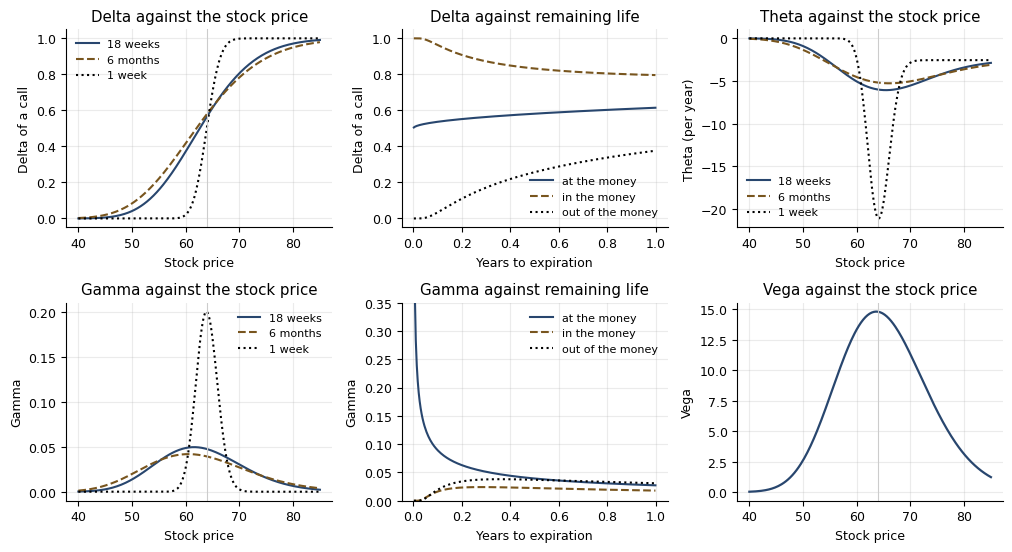

delta of the dealer's option                       0.5199   book       0.5199   ok
gamma of the dealer's option                       0.0489   book       0.0489   ok
theta of the dealer's option, per year            -5.8757   book      -5.8757   ok
gamma peaks at 61.6 on the grid, 61.55 in closed form, against a strike of 64
the grid finds the closed-form peak               61.6000   book      61.5535   ok
gamma peaks below the strike                       1.0000   book       1.0000   ok
at-the-money gamma grows into expiration           1.0000   book       1.0000   ok
out-of-the-money gamma collapses instead           1.0000   book       1.0000   ok


In [7]:
from math import pi


def npdf(x):
    return exp(-0.5 * x * x) / sqrt(2.0 * pi)


def d1_of(S, T, sig=SIGMA):
    return (log(S / K) + (r + 0.5 * sig * sig) * T) / (sig * sqrt(T))


def gamma_call(S, T, sig=SIGMA):
    return npdf(d1_of(S, T, sig)) / (S * sig * sqrt(T))


def theta_call(S, T, sig=SIGMA):
    d1 = d1_of(S, T, sig)
    return -S * npdf(d1) * sig / (2.0 * sqrt(T)) - r * K * exp(-r * T) * N(d1 - sig * sqrt(T))


def vega_call(S, T, sig=SIGMA):
    return S * sqrt(T) * npdf(d1_of(S, T, sig))


spots = [40.0 + 0.2 * i for i in range(226)]          # 40 to 85
lives = [0.002 + 0.004 * i for i in range(250)]       # a few days out to a year

fig, ax = plt.subplots(2, 3, figsize=(10.2, 5.6))

for T, c, ls, lab in ((T0, BLUE, "-", "18 weeks"), (0.5, AMBER, "--", "6 months"),
                      (0.02, "black", ":", "1 week")):
    ax[0, 0].plot(spots, [delta(S, T) for S in spots], color=c, ls=ls, lw=1.5, label=lab)
    ax[1, 0].plot(spots, [gamma_call(S, T) for S in spots], color=c, ls=ls, lw=1.5, label=lab)
    ax[0, 2].plot(spots, [theta_call(S, T) for S in spots], color=c, ls=ls, lw=1.5, label=lab)
ax[0, 0].set_title("Delta against the stock price")
ax[0, 0].set_xlabel("Stock price"); ax[0, 0].set_ylabel("Delta of a call")
ax[1, 0].set_title("Gamma against the stock price")
ax[1, 0].set_xlabel("Stock price"); ax[1, 0].set_ylabel("Gamma")
ax[0, 2].set_title("Theta against the stock price")
ax[0, 2].set_xlabel("Stock price"); ax[0, 2].set_ylabel("Theta (per year)")

for S, c, ls, lab in ((64.0, BLUE, "-", "at the money"), (72.0, AMBER, "--", "in the money"),
                      (56.0, "black", ":", "out of the money")):
    ax[0, 1].plot(lives, [delta(S, T) for T in lives], color=c, ls=ls, lw=1.5, label=lab)
    ax[1, 1].plot(lives, [gamma_call(S, T) for T in lives], color=c, ls=ls, lw=1.5, label=lab)
ax[0, 1].set_title("Delta against remaining life")
ax[0, 1].set_xlabel("Years to expiration"); ax[0, 1].set_ylabel("Delta of a call")
ax[1, 1].set_title("Gamma against remaining life")
ax[1, 1].set_xlabel("Years to expiration"); ax[1, 1].set_ylabel("Gamma")
ax[1, 1].set_ylim(0, 0.35)

ax[1, 2].plot(spots, [vega_call(S, T0) for S in spots], color=BLUE, lw=1.6)
ax[1, 2].set_title("Vega against the stock price")
ax[1, 2].set_xlabel("Stock price"); ax[1, 2].set_ylabel("Vega")

for a in ax.ravel():
    a.axvline(K, color="0.8", lw=0.8) if a.get_xlabel() == "Stock price" else None
for a in (ax[0, 0], ax[1, 0], ax[0, 1], ax[1, 1], ax[0, 2]):
    a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# The three Greeks the chapter states for the dealer's option, at S = 63 and 18 weeks.
show("delta of the dealer's option", delta(S0, T0), 0.5199, 5e-4)
show("gamma of the dealer's option", gamma_call(S0, T0), 0.04886, 5e-5)
show("theta of the dealer's option, per year", theta_call(S0, T0), -5.8757, 5e-3)

# And the shape claims the panels are for, as claims rather than as quoted numbers.
# Gamma peaks a little BELOW the strike, and the offset has a closed form: setting the
# derivative of gamma to zero gives K exp(-(r + 3 sigma^2 / 2) T).
peak = spots[max(range(len(spots)), key=lambda i: gamma_call(spots[i], T0))]
peak_exact = K * exp(-(r + 1.5 * SIGMA ** 2) * T0)
print("gamma peaks at %.1f on the grid, %.2f in closed form, against a strike of %.0f"
      % (peak, peak_exact, K))
show("the grid finds the closed-form peak", peak, peak_exact, 0.3)
show("gamma peaks below the strike", float(peak_exact < K), 1.0, 0.5)
show("at-the-money gamma grows into expiration",
     float(gamma_call(K, 0.02) > gamma_call(K, T0)), 1.0, 0.5)
show("out-of-the-money gamma collapses instead",
     float(gamma_call(56.0, 0.02) < gamma_call(56.0, T0)), 1.0, 0.5)

## Delta as a multiplier, and leverage — Example 18.1

Delta turns a move in the stock into a move in the option; the gap to an exact
repricing is curvature, the gamma term of equation (18.1). Dividing by the option's
value gives its **elasticity**, $\Omega = S\Delta/f$: the percentage change in the
option for a 1% change in the stock, which is its leverage. The plot runs $\Omega$
across strikes at the chapter's inputs: out-of-the-money calls carry the most.

In [ ]:
# Example 18.1: delta as a multiplier, and the call's elasticity (its leverage).
c0, d0 = price, delta(S0, T0)
up = bs_call(S0 + 1.0, K, T0, r, SIGMA) - c0
down = bs_call(S0 - 3.0, K, T0, r, SIGMA) - c0
show("call repriced at 64", bs_call(64.0, K, T0, r, SIGMA), 3.7385, 2e-5)
show("exact rise for a $1 move", up, 0.5442, 1e-4)
show("delta's prediction for a $1 move", d0, 0.5199, 1e-4)
show("gap: curvature", up - d0, 0.0242, 1e-4)
show("gamma / 2, the second-order term", gamma_call(S0, T0) / 2, 0.0244, 1e-4)
show("call repriced at 60", bs_call(60.0, K, T0, r, SIGMA), 1.8568, 2e-5)
show("exact change for a $3 fall", down, -1.3376, 1e-4)
show("delta's prediction for a $3 fall", -3 * round(d0, 4), -1.5597, 1e-4)

omega = S0 * d0 / c0
show("elasticity Omega = S * delta / f", omega, 10.25, 5e-4)
show("exact % rise for a 1% rise (to 63.63)", 100 * (bs_call(63.63, K, T0, r, SIGMA) / c0 - 1), 10.56, 5e-4)
show("call volatility, Omega * sigma, %", 100 * omega * SIGMA, 226, 3e-3)
for k, printed in ((54.0, 5.71), (74.0, 15.98)):
    om = S0 * delta(S0, T0, K=k) / bs_call(S0, k, T0, r, SIGMA)
    show("Omega at strike %g" % k, om, printed, 1e-3)

# Elasticity across strikes: out-of-the-money calls carry the most leverage.
strikes = [50.0 + 0.5 * i for i in range(61)]
fig, ax = plt.subplots()
ax.plot(strikes, [S0 * delta(S0, T0, K=k) / bs_call(S0, k, T0, r, SIGMA) for k in strikes],
        color=BLUE, lw=1.6)
ax.axvline(S0, color="0.8", lw=0.8)
ax.set_xlabel("Strike"); ax.set_ylabel("Elasticity (Omega)")
plt.tight_layout(); plt.show()


## What the hedge costs — Figures 18.1, 18.3, 18.8

Three readings of the same problem. On the left, the two unhedged responses to 100,000 written
calls: doing nothing, and buying the stock outright. Neither is a hedge, and the figure is a
*profit* diagram (the premium is in the plotted quantity), so its breakevens are not the
option's.

In the middle, why a delta hedge is not enough: the option's value is curved and its delta
approximation is a line, so the gap opens in both directions. That gap is gamma, and it is a
loss whichever way the stock moves.

On the right, the cost of the program against how often it is rebalanced, with the chapter's
trading cost of 0.10% of the value of each trade, as in Table 18.7. Rebalancing more often
lowers the standard deviation and raises the mean, so the mean plus one standard deviation has
an interior minimum, near 100 rebalances; that is the whole practical content.

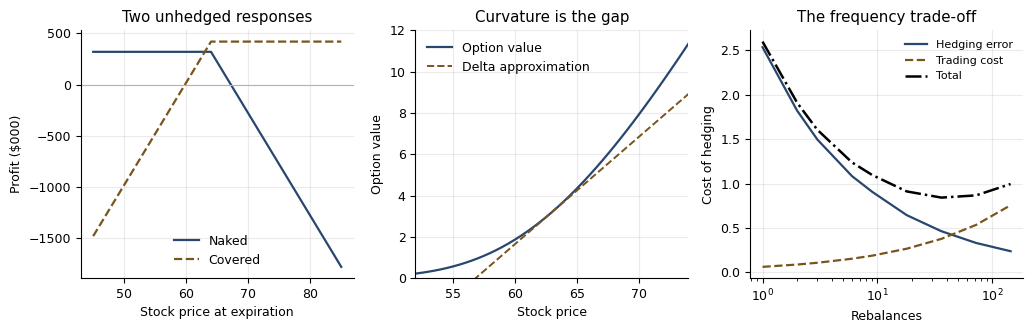

cheapest rebalancing frequency on this grid: 36 times over the option's life
the total has an interior minimum                  1.0000   book       1.0000   ok


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(10.4, 3.4))

# --- Figure 18.1: the two unhedged responses, in thousands of dollars
ST = [45.0 + 0.5 * i for i in range(81)]
naked = [(premium - max(s - K, 0.0) * N_OPT) / 1000.0 for s in ST]
covered = [(premium - max(s - K, 0.0) * N_OPT + (s - S0) * N_OPT) / 1000.0 for s in ST]
ax[0].plot(ST, naked, color=BLUE, lw=1.6, label="Naked")
ax[0].plot(ST, covered, color=AMBER, lw=1.6, ls="--", label="Covered")
ax[0].axhline(0.0, color="0.7", lw=0.8)
ax[0].set_title("Two unhedged responses")
ax[0].set_xlabel("Stock price at expiration"); ax[0].set_ylabel("Profit ($000)")
ax[0].legend(frameon=False)

# --- Figure 18.3: the option's curve against its tangent at 63
tangent = [price + delta(S0, T0) * (s - S0) for s in ST]
curve = [bs_call(s, K, T0, r, SIGMA) for s in ST]
ax[1].plot(ST, curve, color=BLUE, lw=1.6, label="Option value")
ax[1].plot(ST, tangent, color=AMBER, lw=1.4, ls="--", label="Delta approximation")
ax[1].set_xlim(52, 74); ax[1].set_ylim(0, 12)
ax[1].set_title("Curvature is the gap")
ax[1].set_xlabel("Stock price"); ax[1].set_ylabel("Option value")
ax[1].legend(frameon=False)

# --- Figure 18.8: cost against rebalancing frequency, with the chapter's trading cost
COST_RATE = 0.0010                                     # 0.10% of the value of each trade
counts = [5, 10, 20, 50, 100, 250]
TABLE_18_7 = {5: 4.4552, 10: 4.1560, 20: 3.9370, 50: 3.7760, 100: 3.7242, 250: 3.7689}
means, totals = [], []
for n_reb in counts:
    c = hedge_cost_mc(n_reb, n_paths=10_000, cost_rate=COST_RATE)
    means.append(c.mean())
    totals.append(c.mean() + c.std())
ax[2].plot(counts, totals, color=AMBER, lw=1.6, ls="-.", marker="o", ms=3, label="Mean + s.d.")
ax[2].plot(counts, means, color=BLUE, lw=1.6, marker="o", ms=3, label="Mean cost")
ax[2].axhline(price, color="0.6", lw=1.0, ls="--", label="Formula value")
ax[2].set_xscale("log")
ax[2].set_title("The frequency trade-off")
ax[2].set_xlabel("Rebalances"); ax[2].set_ylabel("Cost of hedging")
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

best = counts[min(range(len(totals)), key=lambda i: totals[i])]
print("cheapest rebalancing frequency (mean + s.d.): %d times over the option's life" % best)
show("cheapest at 100 rebalances, as in Table 18.7", float(best == 100), 1.0, 0.5)
for n_reb, tot in zip(counts, totals):
    show("n = %3d: mean + s.d., Table 18.7" % n_reb, tot, TABLE_18_7[n_reb], 0.01)